# NFL vs `NFL_REWORKED`: walidacja z poprawionym Testem B i skończonym polem

Ten notebook rozszerza poprzednią walidację o dwa elementy:

1. testy dla skończonego pola $H_a \neq 0$,
2. **odporniejszą** wersję Testu B.

W praktyce maksymalny residual logarytmiczny liczony na zbyt szerokiej masce (np. z progiem $10^{-12}$) bywa zdominowany przez prawie puste / prawie pełne stany. Dla poprawnej implementacji zamkniętej postaci może to dawać fałszywie negatywny wynik `False`, mimo że wzór paramagnetyczny i ograniczenia fizyczne są spełnione. Dlatego w tym notebooku Test B jest oceniany na **masce wewnętrznej** (core mask), a szersza maska jest zachowana tylko diagnostycznie.

W całym notebooku używamy tej samej konwencji co w `nfl_reworked.cpp`:

$$
\mu_\sigma = \mu - \sigma\,\delta,
\qquad
\epsilon_{k,\sigma} = \epsilon_k + \sigma\,\delta,
$$

oraz

$$
\delta = \frac12 g \mu_B H_a.
$$


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import qss
from qss import chemical_potential
from qss.distributions import DistType, distribution, prepare_2D_lattice_data
from qss.entropy import entropy

print("python:", sys.executable)
print("cwd:", Path.cwd())
print("qss:", qss.__file__)
print("available DistType:", [member.name for member in DistType])

assert hasattr(DistType, "NFL_REWORKED"), "Current qss install does not expose NFL_REWORKED"


python: /home/piotr/Documents/github/quantum-statistics-solver_workingcopy/.venv/bin/python
cwd: /home/piotr/Documents/github/quantum-statistics-solver/notebooks
qss: /home/piotr/Documents/github/quantum-statistics-solver_workingcopy/.venv/lib/python3.11/site-packages/qss/__init__.py
available DistType: ['FD', 'FLB', 'NFL', 'NFL_REWORKED', 'NFLB', 'SSL', 'HUBBARD']


In [2]:
N = 80
kx = np.linspace(-np.pi, np.pi, N)
ky = np.linspace(-np.pi, np.pi, N)
E, KX, KY = prepare_2D_lattice_data(kx, ky, t=-1.0, t_prim=0.25)

distros = [DistType.NFL, DistType.NFL_REWORKED]
n_vals = np.linspace(0.05, 0.95, 19)
kBT_vals = [0.1, 0.2, 0.5]
H_a_vals = [0.0, 0.05, 0.10]

mu_probe = 0.0
kBT_probe = 0.2
delta_probe = 0.05
e_probe = np.linspace(-4.0, 4.0, 600)


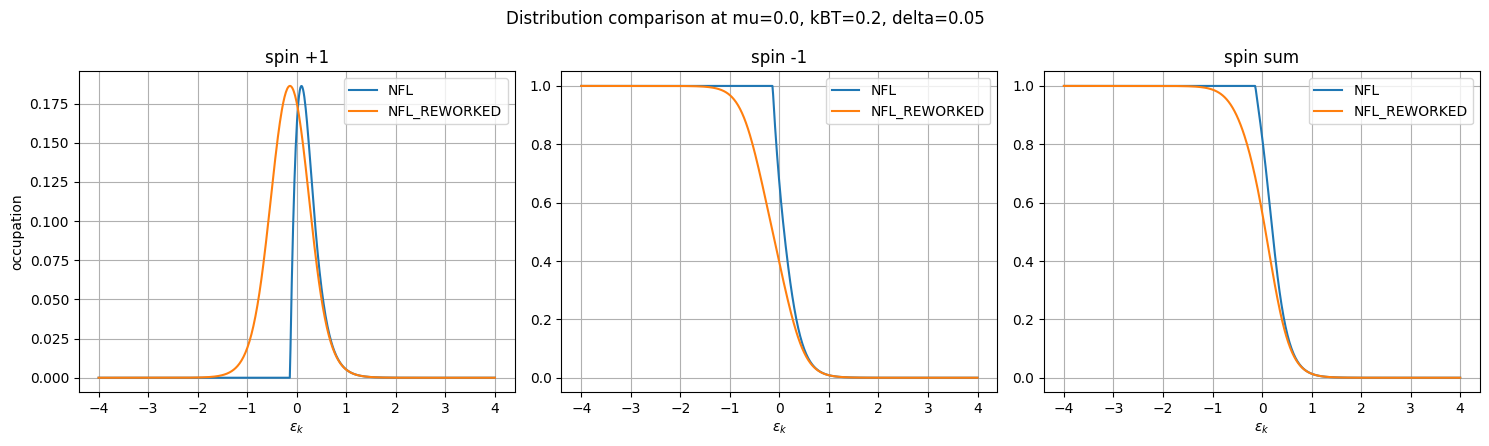

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)

for distro in distros:
    up = distribution(e_probe, mu=mu_probe, kBT=kBT_probe, delta=delta_probe, spin_shift=1, dist_type=distro)
    down = distribution(e_probe, mu=mu_probe, kBT=kBT_probe, delta=delta_probe, spin_shift=-1, dist_type=distro)
    total = up + down

    axes[0].plot(e_probe, up, label=distro.name)
    axes[1].plot(e_probe, down, label=distro.name)
    axes[2].plot(e_probe, total, label=distro.name)

axes[0].set_title("spin +1")
axes[1].set_title("spin -1")
axes[2].set_title("spin sum")

for ax in axes:
    ax.set_xlabel(r"$\epsilon_k$")
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel("occupation")
plt.suptitle(f"Distribution comparison at mu={mu_probe}, kBT={kBT_probe}, delta={delta_probe}")
plt.tight_layout()


In [4]:
mu_df = chemical_potential(
    distros=distros,
    n_vals=n_vals,
    kBT_vals=kBT_vals,
    H_a_vals=H_a_vals,
    E=E,
)

mu_df.head(10)

mu  iterations  converged      residual
distro n    k_BT H_a                                               
NFL    0.05 0.1  0.0 -2.639082          35       True  4.097833e-12
       0.10 0.1  0.0 -2.212238          35       True  2.506721e-11
       0.15 0.1  0.0 -1.822178          35       True  8.575216e-11
       0.20 0.1  0.0 -1.467207          32       True  5.872242e-11
       0.25 0.1  0.0 -1.146516          34       True  1.743250e-11
       0.30 0.1  0.0 -0.859831          36       True  5.179501e-11
       0.35 0.1  0.0 -0.607917          32       True  3.549888e-11
       0.40 0.1  0.0 -0.393207          37       True  1.827261e-11
       0.45 0.1  0.0 -0.217008          38       True  2.043626e-11
       0.50 0.1  0.0 -0.067806          40       True  2.557787e-12

In [5]:
comparison = (
    mu_df.reset_index()
    .pivot_table(index=["n", "k_BT", "H_a"], columns="distro", values="mu")
    .assign(delta_mu=lambda df: df["NFL_REWORKED"] - df["NFL"])
)

comparison.head(10)

distro               NFL  NFL_REWORKED  delta_mu
n    k_BT H_a                                   
0.05 0.1  0.00 -2.639082     -2.551471  0.087612
          0.05 -2.687218     -2.591279  0.095940
          0.10 -2.737427     -2.640392  0.097036
     0.2  0.00 -2.759475     -2.627767  0.131709
          0.05 -2.792908     -2.644221  0.148688
          0.10 -2.841582     -2.680887  0.160695
     0.5  0.00 -3.282166     -3.120809  0.161358
          0.05 -3.286510     -3.124444  0.162066
          0.10 -3.299256     -3.135159  0.164097
0.10 0.1  0.00 -2.212238     -2.117243  0.094994

## Testy walidacyjne dla rozwiązania z licznikiem $(1-n_k)^2$

Walidujemy jądro `NFL_REWORKED` przeciwko równaniu stacjonarności zadeklarowanemu w `nfl_reworked.cpp`:

$$
\frac{(1-n_k)^2}{n_{k,\sigma}(1-n_{k,\sigma})}
= \exp\!\left[\frac{\epsilon_k + \sigma\,\delta - \mu}{k_B T}\right],
\qquad
n_k = n_{k,+} + n_{k,-} \le 1.
$$

Sprawdzamy cztery rzeczy:

- **Test A**: dla $\delta = 0$ zgodność z postacią zamkniętą,
  $$
  n_{k,\sigma}^{\mathrm{closed}}
  = \frac12\left(1-\frac{1}{\sqrt{1+4e^{(\mu-\epsilon_k)/(k_B T)}}}\right).
  $$
- **Test B**: residual logarytmiczny równania stacjonarności,
  $$
  r_{k,\sigma}^{\log}
  = 2\ln(1-n_k) - \ln n_{k,\sigma} - \ln(1-n_{k,\sigma})
    - \frac{\epsilon_k + \sigma\,\delta - \mu}{k_B T}.
  $$
- **Test C**: degeneracja spinowa przy $\delta = 0$,
  $$
  n_{k,+} = n_{k,-}.
  $$
- **Test D**: ograniczenia fizyczne,
  $$
  0 \le n_{k,\sigma} \le 1,
  \qquad
  0 \le n_k \le 1.
  $$

Ważny detal praktyczny: Test B oceniamy na **masce wewnętrznej**
$$
\varepsilon_{\mathrm{core}} = 10^{-8},
$$
a szerszą maskę
$$
\varepsilon_{\mathrm{wide}} = 10^{-10}
$$
traktujemy tylko diagnostycznie. Dzięki temu unikamy fałszywych alarmów od punktów, gdzie $n_{k,\sigma}$ lub $1-n_k$ jest ekstremalnie małe i sama forma logarytmiczna wzmacnia błąd zaokrągleń.


In [6]:
def zeeman_delta_from_Ha(H_a, g=2.0, muB_eV_per_T=1.0):
    """Match the default H_a -> delta convention used in qss.entropy."""
    return 0.5 * g * muB_eV_per_T * H_a


def nfl_reworked_paramagnetic_single_spin(E, mu, kBT):
    """Closed-form single-spin occupation for the paramagnetic squared-numerator model."""
    E = np.asarray(E, dtype=float)
    exponent = np.clip((mu - E) / kBT, -700.0, 700.0)
    return 0.5 * (1.0 - 1.0 / np.sqrt(1.0 + 4.0 * np.exp(exponent)))


def compute_spin_channels(E, mu, kBT, delta, distro):
    n_plus = distribution(E, mu=mu, kBT=kBT, delta=delta, spin_shift=1, dist_type=distro)
    n_minus = distribution(E, mu=mu, kBT=kBT, delta=delta, spin_shift=-1, dist_type=distro)
    n_tot = n_plus + n_minus
    vacancy = 1.0 - n_tot
    return n_plus, n_minus, n_tot, vacancy


def stationary_log_residuals(E, mu, kBT, delta, distro, eps=1e-8):
    """Pointwise log-residuals of the stationary equation on an interior mask."""
    E = np.asarray(E, dtype=float)
    n_plus, n_minus, n_tot, vacancy = compute_spin_channels(E, mu, kBT, delta, distro)

    def _single_channel(n_sigma, sigma):
        mask = (vacancy > eps) & (n_sigma > eps) & (n_sigma < 1.0 - eps)
        residual = np.full(E.shape, np.nan, dtype=float)
        if np.any(mask):
            residual[mask] = (
                2.0 * np.log(vacancy[mask])
                - np.log(n_sigma[mask])
                - np.log(1.0 - n_sigma[mask])
                - (E[mask] + sigma * delta - mu) / kBT
            )
        return residual, mask

    r_plus, mask_plus = _single_channel(n_plus, +1)
    r_minus, mask_minus = _single_channel(n_minus, -1)

    return {
        "n_plus": n_plus,
        "n_minus": n_minus,
        "n_tot": n_tot,
        "vacancy": vacancy,
        "r_plus": r_plus,
        "r_minus": r_minus,
        "mask_plus": mask_plus,
        "mask_minus": mask_minus,
    }


def _masked_residual_metrics(diag, prefix):
    residual_chunks = []
    if np.any(diag["mask_plus"]):
        residual_chunks.append(diag["r_plus"][diag["mask_plus"]].ravel())
    if np.any(diag["mask_minus"]):
        residual_chunks.append(diag["r_minus"][diag["mask_minus"]].ravel())

    if residual_chunks:
        all_residuals = np.concatenate(residual_chunks)
        return {
            f"max_abs_log_residual_{prefix}": float(np.max(np.abs(all_residuals))),
            f"rms_log_residual_{prefix}": float(np.sqrt(np.mean(all_residuals ** 2))),
            f"valid_fraction_{prefix}": float((diag["mask_plus"].sum() + diag["mask_minus"].sum()) / (2.0 * diag["n_tot"].size)),
        }

    return {
        f"max_abs_log_residual_{prefix}": np.nan,
        f"rms_log_residual_{prefix}": np.nan,
        f"valid_fraction_{prefix}": 0.0,
    }


def summarize_validation(E, mu, kBT, delta, distro, eps_core=1e-8, eps_wide=1e-10):
    diag_core = stationary_log_residuals(E, mu=mu, kBT=kBT, delta=delta, distro=distro, eps=eps_core)
    diag_wide = stationary_log_residuals(E, mu=mu, kBT=kBT, delta=delta, distro=distro, eps=eps_wide)

    out = {}
    out.update(_masked_residual_metrics(diag_core, "core"))
    out.update(_masked_residual_metrics(diag_wide, "wide"))

    n_plus = diag_core["n_plus"]
    n_minus = diag_core["n_minus"]
    n_tot = diag_core["n_tot"]
    vacancy = diag_core["vacancy"]

    lower_single_violation = float(max(0.0, -np.min(n_plus), -np.min(n_minus)))
    upper_single_violation = float(max(0.0, np.max(n_plus) - 1.0, np.max(n_minus) - 1.0))
    lower_total_violation = float(max(0.0, -np.min(n_tot)))
    upper_total_violation = float(max(0.0, np.max(n_tot) - 1.0))
    max_bound_violation = float(
        max(lower_single_violation, upper_single_violation, lower_total_violation, upper_total_violation)
    )

    out.update(
        {
            "min_single_occ": float(min(np.min(n_plus), np.min(n_minus))),
            "max_single_occ": float(max(np.max(n_plus), np.max(n_minus))),
            "min_total_occ": float(np.min(n_tot)),
            "max_total_occ": float(np.max(n_tot)),
            "min_vacancy": float(np.min(vacancy)),
            "max_bound_violation": max_bound_violation,
            "any_non_finite": bool(
                np.any(~np.isfinite(n_plus))
                or np.any(~np.isfinite(n_minus))
                or np.any(~np.isfinite(n_tot))
                or np.any(~np.isfinite(vacancy))
            ),
        }
    )

    if np.isclose(delta, 0.0):
        n_ref = nfl_reworked_paramagnetic_single_spin(E, mu, kBT)
        err_plus = n_plus - n_ref
        err_minus = n_minus - n_ref
        out["max_abs_paramagnetic_err"] = float(max(np.max(np.abs(err_plus)), np.max(np.abs(err_minus))))
        out["rms_paramagnetic_err"] = float(
            np.sqrt(np.mean(np.concatenate([err_plus.ravel(), err_minus.ravel()]) ** 2))
        )
        out["spin_degeneracy_max_err"] = float(np.max(np.abs(n_plus - n_minus)))
    else:
        out["max_abs_paramagnetic_err"] = np.nan
        out["rms_paramagnetic_err"] = np.nan
        out["spin_degeneracy_max_err"] = np.nan

    return out


In [7]:
validation_records = []

for (distro, n_target, kBT, H_a), row in mu_df.iterrows():
    delta = zeeman_delta_from_Ha(H_a)
    metrics = summarize_validation(E, mu=row["mu"], kBT=kBT, delta=delta, distro=distro)
    validation_records.append(
        {
            "distro": distro,
            "n": n_target,
            "k_BT": kBT,
            "H_a": H_a,
            **metrics,
        }
    )

validation_checks = (
    pd.DataFrame(validation_records)
    .set_index(["distro", "n", "k_BT", "H_a"])
    .sort_index()
)

validation_view = pd.concat(
    {
        "mu": comparison[["NFL", "NFL_REWORKED", "delta_mu"]],
        "max_abs_log_residual_core": validation_checks.reset_index().pivot_table(
            index=["n", "k_BT", "H_a"], columns="distro", values="max_abs_log_residual_core"
        )[["NFL", "NFL_REWORKED"]],
        "max_abs_log_residual_wide": validation_checks.reset_index().pivot_table(
            index=["n", "k_BT", "H_a"], columns="distro", values="max_abs_log_residual_wide"
        )[["NFL", "NFL_REWORKED"]],
        "max_abs_paramagnetic_err": validation_checks.reset_index().pivot_table(
            index=["n", "k_BT", "H_a"], columns="distro", values="max_abs_paramagnetic_err"
        )[["NFL", "NFL_REWORKED"]],
        "spin_degeneracy_max_err": validation_checks.reset_index().pivot_table(
            index=["n", "k_BT", "H_a"], columns="distro", values="spin_degeneracy_max_err"
        )[["NFL", "NFL_REWORKED"]],
        "max_bound_violation": validation_checks.reset_index().pivot_table(
            index=["n", "k_BT", "H_a"], columns="distro", values="max_bound_violation"
        )[["NFL", "NFL_REWORKED"]],
    },
    axis=1,
)

validation_view.head(12)


mu                        max_abs_log_residual_core  \
distro               NFL NFL_REWORKED  delta_mu                       NFL   
n    k_BT H_a                                                               
0.05 0.1  0.00 -2.639082    -2.551471  0.087612                  4.971801   
          0.05 -2.687218    -2.591279  0.095940                  2.738575   
          0.10 -2.737427    -2.640392  0.097036                  3.093006   
     0.2  0.00 -2.759475    -2.627767  0.131709                  2.582785   
          0.05 -2.792908    -2.644221  0.148688                  3.887976   
          0.10 -2.841582    -2.680887  0.160695                  4.658798   
     0.5  0.00 -3.282166    -3.120809  0.161358                  0.971766   
          0.05 -3.286510    -3.124444  0.162066                  0.980122   
          0.10 -3.299256    -3.135159  0.164097                  1.004565   
0.10 0.1  0.00 -2.212238    -2.117243  0.094994                  9.240200   
          0.05 -2.260849    -2.163825  0.097024                  3.176565   
          0.10 -2.310621    -2.213245  0.097376                  4.000805   

                             max_abs_log_residual_wide                \
distro          NFL_REWORKED                       NFL  NFL_REWORKED   
n    k_BT H_a                                                          
0.05 0.1  0.00  2.148354e-09                  4.971801  2.622625e-07   
          0.05  2.376378e-09                  2.738575  2.614846e-07   
          0.10  2.565553e-09                  3.093006  2.520702e-07   
     0.2  0.00  1.769511e-09                  2.582785  1.626418e-07   
          0.05  1.893245e-09                  3.887976  2.392130e-07   
          0.10  2.675293e-09                  4.658798  2.213809e-07   
     0.5  0.00  4.540368e-12                  0.971766  4.540368e-12   
          0.05  6.274092e-12                  0.980122  6.274092e-12   
          0.10  6.485479e-12                  1.004565  6.485479e-12   
0.10 0.1  0.00  2.508454e-09                  9.240200  2.248006e-07   
          0.05  2.367624e-09                  3.176565  1.945549e-07   
          0.10  2.257835e-09                  4.000805  2.370867e-07   

               max_abs_paramagnetic_err               spin_degeneracy_max_err  \
distro                              NFL  NFL_REWORKED                     NFL   
n    k_BT H_a                                                                   
0.05 0.1  0.00                 0.108023  1.110223e-16                     0.0   
          0.05                      NaN           NaN                     NaN   
          0.10                      NaN           NaN                     NaN   
     0.2  0.00                 0.108002  1.110223e-16                     0.0   
          0.05                      NaN           NaN                     NaN   
          0.10                      NaN           NaN                     NaN   
     0.5  0.00                 0.087539  1.110223e-16                     0.0   
          0.05                      NaN           NaN                     NaN   
          0.10                      NaN           NaN                     NaN   
0.10 0.1  0.00                 0.107994  1.110223e-16                     0.0   
          0.05                      NaN           NaN                     NaN   
          0.10                      NaN           NaN                     NaN   

                            max_bound_violation               
distro         NFL_REWORKED                 NFL NFL_REWORKED  
n    k_BT H_a                                                 
0.05 0.1  0.00          0.0                 0.0          0.0  
          0.05          NaN                 0.0          0.0  
          0.10          NaN                 0.0          0.0  
     0.2  0.00          0.0                 0.0          0.0  
          0.05          NaN                 0.0          0.0  
          0.10          NaN                 0.0          0.0  
  


## Uwaga organizacyjna

W tym notebooku **nie zmieniamy konwencji znaków w projekcie**.  
Walidujemy `NFL_REWORKED` w obecnym interfejsie tak, jak jest podpięty przez `DistType.NFL_REWORKED`.

To oznacza:

- `NFL_REWORKED` pozostaje **dodatkowym** rozkładem do porównania ze starym `NFL`,
- testy A–D służą do oceny poprawności nowego kernela,
- ewentualną pełną unifikację znaków w pomocniczych modułach (`energy.py` itd.) odkładamy jako osobny krok.

Dla pass/fail używamy teraz wyłącznie `max_abs_log_residual_core`.  
Szeroka maska (`wide`) zostaje tylko diagnostycznie.


## Podsumowanie pass/fail dla `NFL_REWORKED`

Stosujemy praktyczne tolerancje:

$$
\texttt{TOL\_LOG\_RESIDUAL\_CORE} = 10^{-7},
\qquad
\texttt{TOL\_PARAMAG} = 10^{-10},
\qquad
\texttt{TOL\_DEGENERACY} = 10^{-10},
\qquad
\texttt{TOL\_BOUNDS} = 10^{-12}.
$$

Interpretacja:

- dla wszystkich $H_a$ sprawdzamy Test B i Test D,
- dla $H_a = 0$ dodatkowo sprawdzamy Test A i Test C,
- szeroka maska residualu (`wide`) zostaje jako diagnostyka, ale **nie** decyduje o pass/fail.


In [8]:
TOL_LOG_RESIDUAL_CORE = 1e-7
TOL_PARAMAG = 1e-10
TOL_DEGENERACY = 1e-10
TOL_BOUNDS = 1e-12

reworked_checks = validation_checks.xs("NFL_REWORKED", level="distro").copy()

zero_field_checks = reworked_checks.xs(0.0, level="H_a", drop_level=False).copy()
finite_field_checks = reworked_checks[reworked_checks.index.get_level_values("H_a") > 0.0].copy()

zero_field_pass_fail = pd.DataFrame(
    {
        "A_paramagnetic_closed_form": zero_field_checks["max_abs_paramagnetic_err"] < TOL_PARAMAG,
        "B_stationary_log_residual_core": zero_field_checks["max_abs_log_residual_core"] < TOL_LOG_RESIDUAL_CORE,
        "C_spin_degeneracy": zero_field_checks["spin_degeneracy_max_err"] < TOL_DEGENERACY,
        "D_physical_bounds": zero_field_checks["max_bound_violation"] < TOL_BOUNDS,
    },
    index=zero_field_checks.index,
)
zero_field_pass_fail["all_tests_pass"] = zero_field_pass_fail.all(axis=1)

if len(finite_field_checks) > 0:
    finite_field_pass_fail = pd.DataFrame(
        {
            "B_stationary_log_residual_core": finite_field_checks["max_abs_log_residual_core"] < TOL_LOG_RESIDUAL_CORE,
            "D_physical_bounds": finite_field_checks["max_bound_violation"] < TOL_BOUNDS,
        },
        index=finite_field_checks.index,
    )
    finite_field_pass_fail["all_applicable_tests_pass"] = finite_field_pass_fail.all(axis=1)
else:
    finite_field_pass_fail = pd.DataFrame()

validation_summary_zero_field = pd.Series(
    {
        "A_paramagnetic_closed_form_all": bool(zero_field_pass_fail["A_paramagnetic_closed_form"].all()),
        "B_stationary_log_residual_core_all": bool(zero_field_pass_fail["B_stationary_log_residual_core"].all()),
        "C_spin_degeneracy_all": bool(zero_field_pass_fail["C_spin_degeneracy"].all()),
        "D_physical_bounds_all": bool(zero_field_pass_fail["D_physical_bounds"].all()),
        "all_zero_field_rows_pass": bool(zero_field_pass_fail["all_tests_pass"].all()),
    },
    name="NFL_REWORKED_zero_field",
)

validation_summary_finite_field = pd.Series(
    {
        "B_stationary_log_residual_core_all": bool(finite_field_pass_fail.get("B_stationary_log_residual_core", pd.Series(dtype=bool)).all()) if len(finite_field_pass_fail) else True,
        "D_physical_bounds_all": bool(finite_field_pass_fail.get("D_physical_bounds", pd.Series(dtype=bool)).all()) if len(finite_field_pass_fail) else True,
        "all_finite_field_rows_pass": bool(finite_field_pass_fail.get("all_applicable_tests_pass", pd.Series(dtype=bool)).all()) if len(finite_field_pass_fail) else True,
    },
    name="NFL_REWORKED_finite_field",
)

zero_field_pass_fail.head(12), finite_field_pass_fail.head(12), validation_summary_zero_field, validation_summary_finite_field


(               A_paramagnetic_closed_form  B_stationary_log_residual_core  \
 n    k_BT H_a                                                               
 0.05 0.1  0.0                        True                            True   
      0.2  0.0                        True                            True   
      0.5  0.0                        True                            True   
 0.10 0.1  0.0                        True                            True   
      0.2  0.0                        True                            True   
      0.5  0.0                        True                            True   
 0.15 0.1  0.0                        True                            True   
      0.2  0.0                        True                            True   
      0.5  0.0                        True                            True   
 0.20 0.1  0.0                        True                            True   
      0.2  0.0                        True                      

In [9]:

compact_validation_summary = pd.DataFrame(
    {
        "zero_field_all_pass": [bool(validation_summary_zero_field["all_zero_field_rows_pass"])],
        "finite_field_all_pass": [bool(validation_summary_finite_field["all_finite_field_rows_pass"])],
        "max_core_residual_zero_field": [float(zero_field_checks["max_abs_log_residual_core"].max())],
        "max_core_residual_finite_field": [float(finite_field_checks["max_abs_log_residual_core"].max()) if len(finite_field_checks) else np.nan],
        "max_bound_violation_zero_field": [float(zero_field_checks["max_bound_violation"].max())],
        "max_bound_violation_finite_field": [float(finite_field_checks["max_bound_violation"].max()) if len(finite_field_checks) else np.nan],
    },
    index=["NFL_REWORKED"],
)
compact_validation_summary


,zero_field_all_pass,finite_field_all_pass,max_core_residual_zero_field,max_core_residual_finite_field,max_bound_violation_zero_field,max_bound_violation_finite_field
NFL_REWORKED,True,True,9.952664e-09,7.888580e-08,0.0,0.0


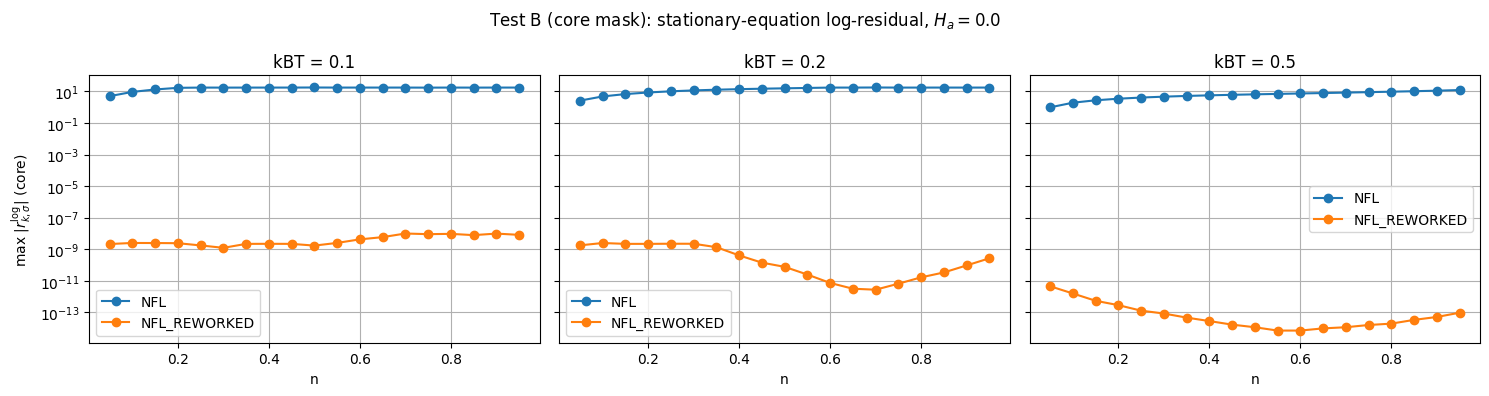

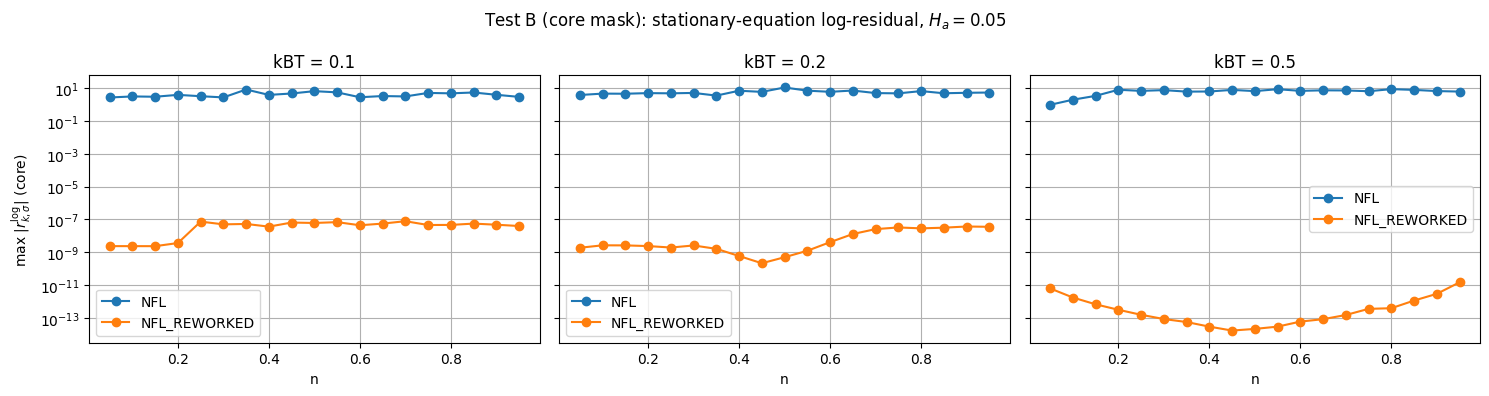

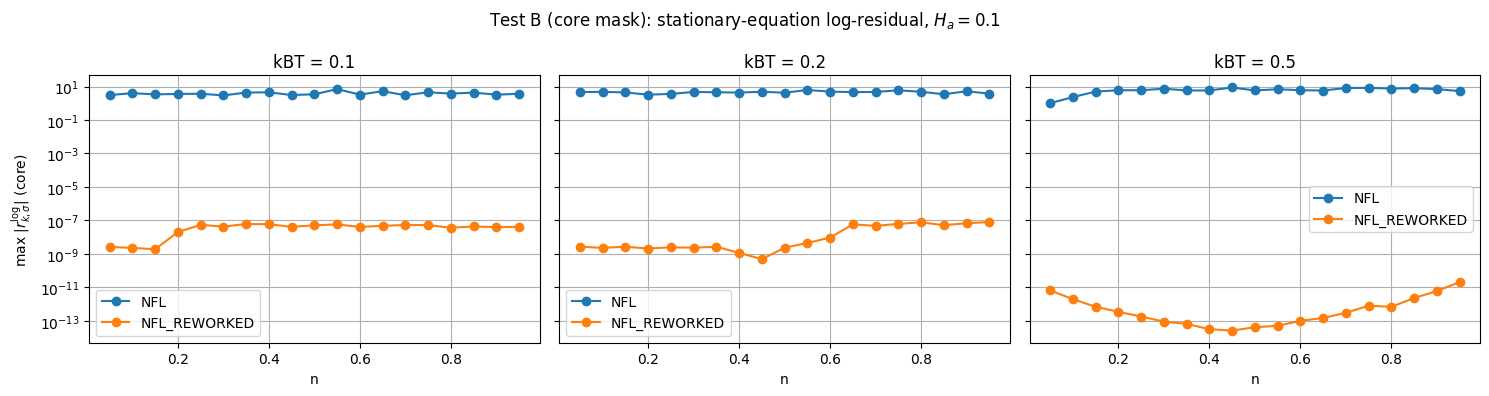

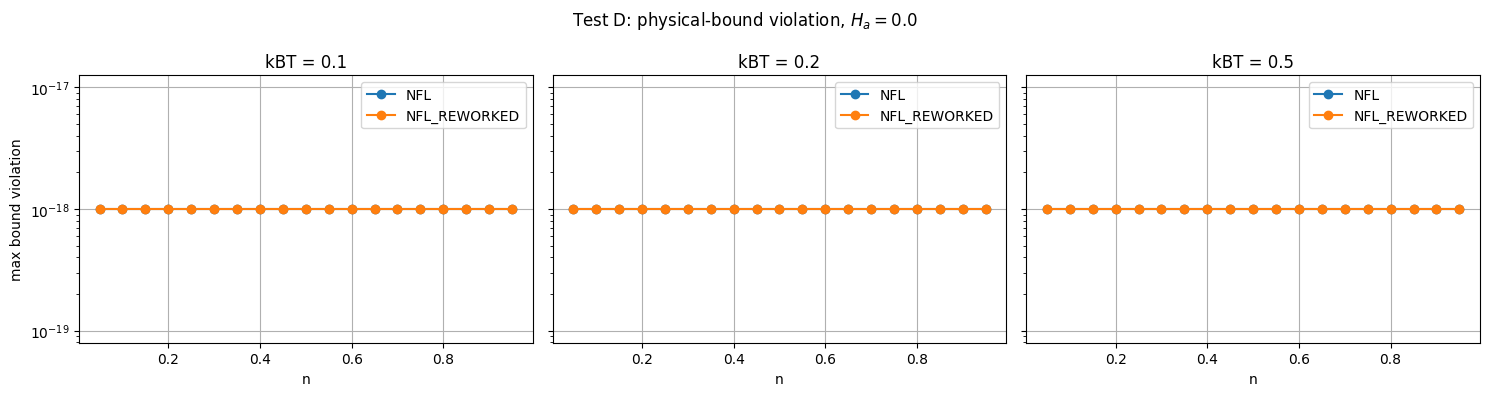

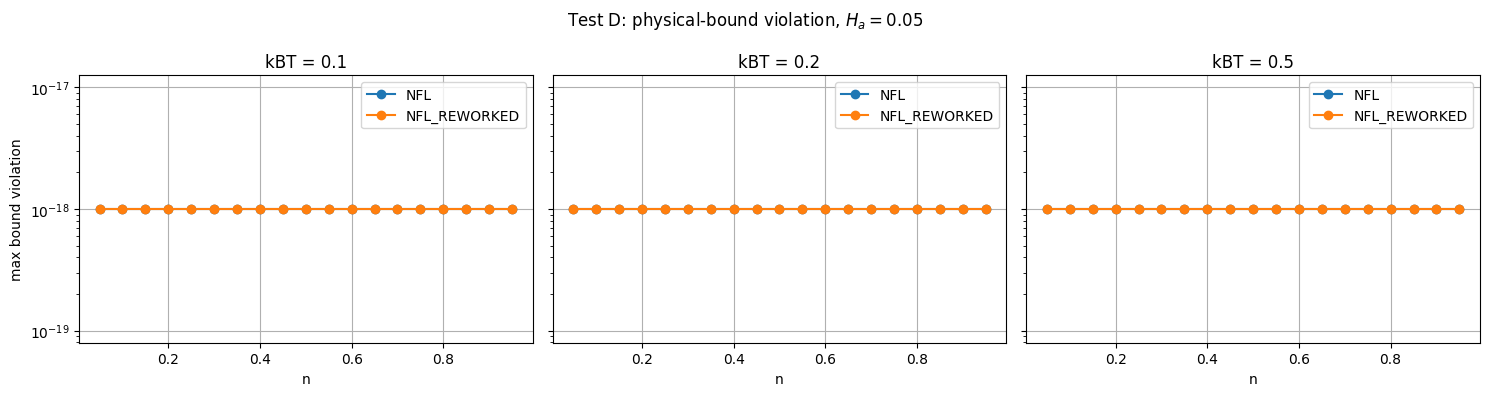

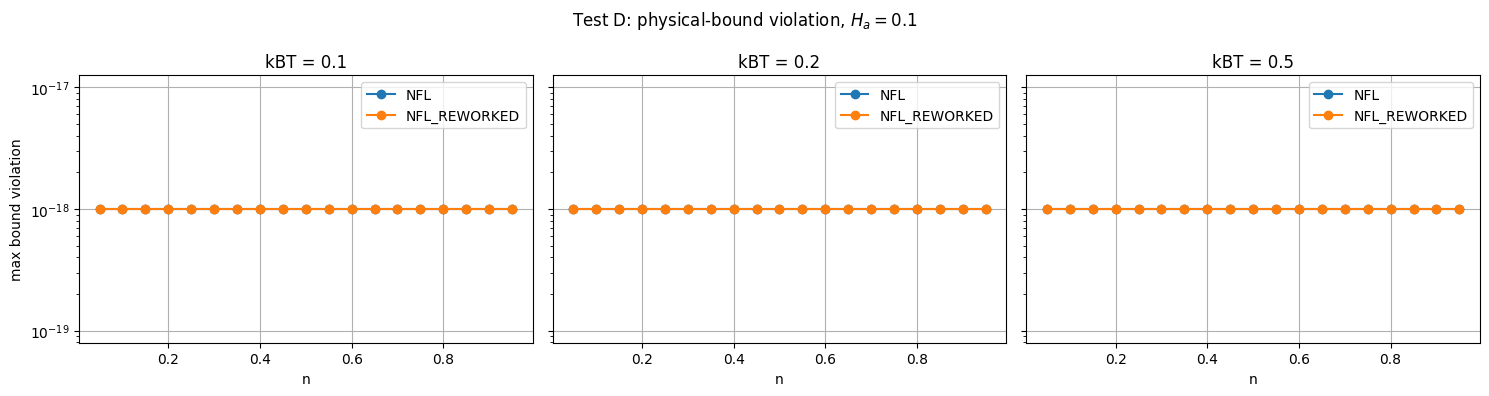

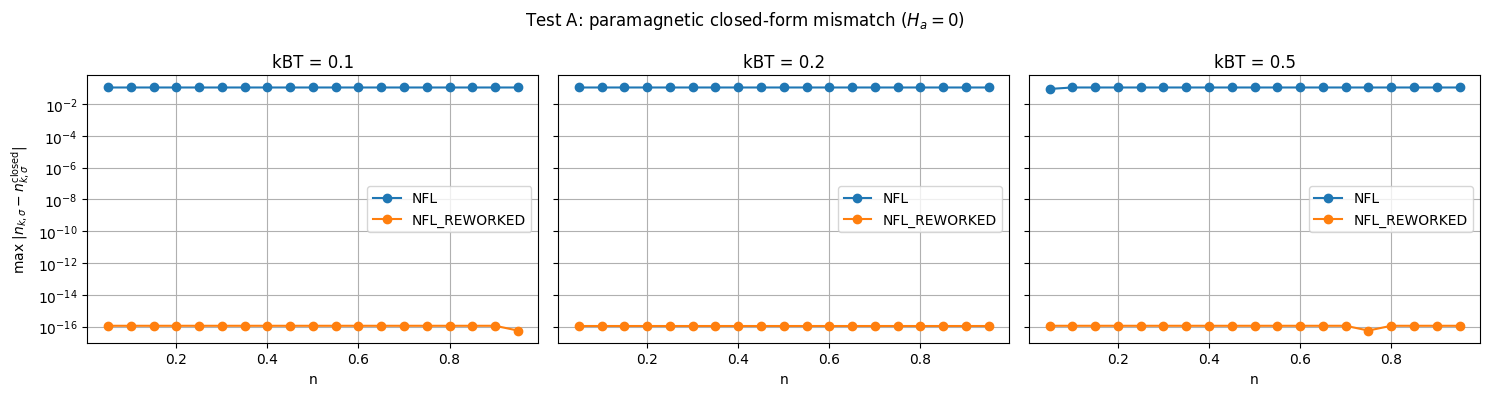

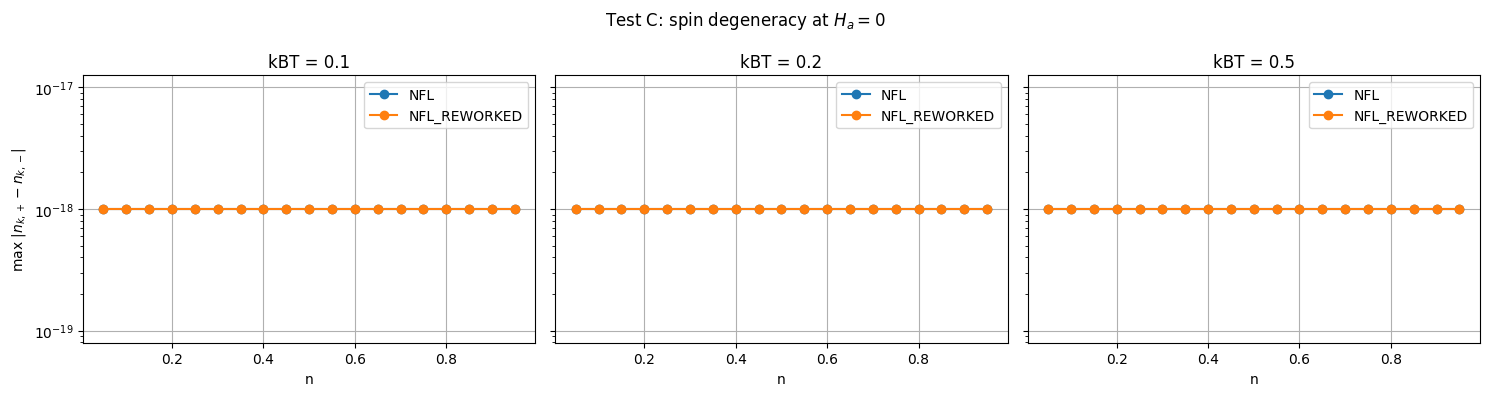

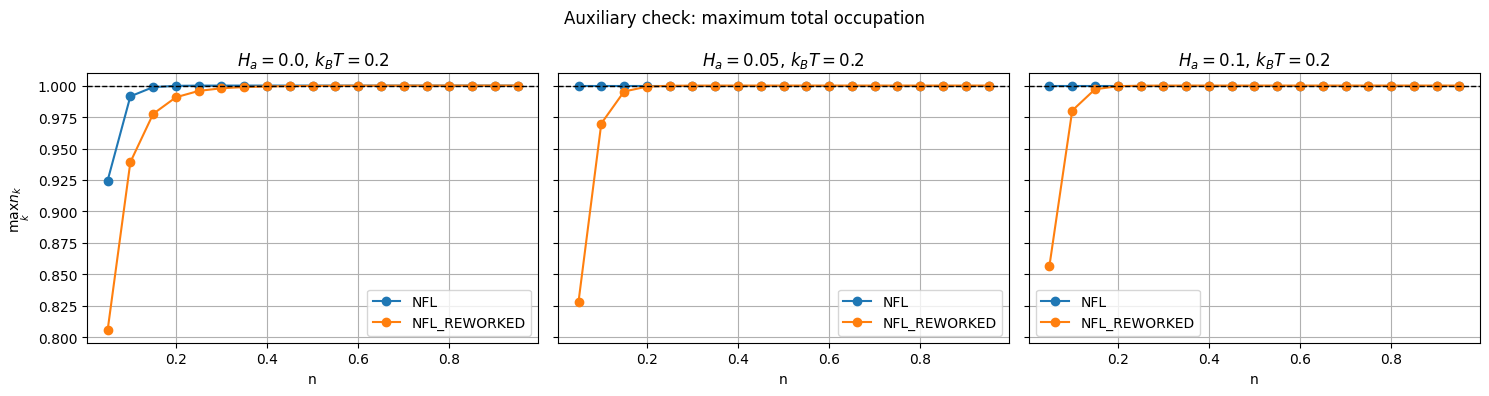

In [10]:
for H_a in H_a_vals:
    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, kBT in zip(axes, kBT_vals):
        subset = validation_checks.xs((kBT, H_a), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            values = np.maximum(block["max_abs_log_residual_core"].values.astype(float), 1e-18)
            ax.semilogy(block.index.values, values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()
    axes[0].set_ylabel(r"max $|r^{\log}_{k,\sigma}|$ (core)")
    plt.suptitle(rf"Test B (core mask): stationary-equation log-residual, $H_a = {H_a}$")
    plt.tight_layout()

for H_a in H_a_vals:
    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, kBT in zip(axes, kBT_vals):
        subset = validation_checks.xs((kBT, H_a), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            values = np.maximum(block["max_bound_violation"].values.astype(float), 1e-18)
            ax.semilogy(block.index.values, values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()
    axes[0].set_ylabel("max bound violation")
    plt.suptitle(rf"Test D: physical-bound violation, $H_a = {H_a}$")
    plt.tight_layout()

if 0.0 in H_a_vals:
    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, kBT in zip(axes, kBT_vals):
        subset = validation_checks.xs((kBT, 0.0), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            values = np.maximum(block["max_abs_paramagnetic_err"].values.astype(float), 1e-18)
            ax.semilogy(block.index.values, values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()
    axes[0].set_ylabel(r"max $|n_{k,\sigma}-n^{\mathrm{closed}}_{k,\sigma}|$")
    plt.suptitle(r"Test A: paramagnetic closed-form mismatch ($H_a = 0$)")
    plt.tight_layout()

    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, kBT in zip(axes, kBT_vals):
        subset = validation_checks.xs((kBT, 0.0), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            values = np.maximum(block["spin_degeneracy_max_err"].values.astype(float), 1e-18)
            ax.semilogy(block.index.values, values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()
    axes[0].set_ylabel(r"max $|n_{k,+}-n_{k,-}|$")
    plt.suptitle(r"Test C: spin degeneracy at $H_a = 0$")
    plt.tight_layout()

fig, axes = plt.subplots(1, len(H_a_vals), figsize=(5 * len(H_a_vals), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, H_a in zip(axes, H_a_vals):
    subset = validation_checks.xs((0.2, H_a), level=("k_BT", "H_a"))
    for distro in distros:
        block = subset.xs(distro.name, level="distro")
        ax.plot(block.index.values, block["max_total_occ"].values, marker="o", label=distro.name)
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0)
    ax.set_title(rf"$H_a = {H_a}$, $k_BT=0.2$")
    ax.set_xlabel("n")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel(r"$\max_k n_k$")
plt.suptitle("Auxiliary check: maximum total occupation")
plt.tight_layout()


## Opcjonalny gęsty skan entropii przy $n \to 1$ i dla skończonego pola

Jeżeli chcesz lepiej zobaczyć zachowanie entropii blisko $n \to 1$, poniższa sekcja liczy $\mu(n,T)$ i średnią entropię na gęstszej siatce wypełnień. Dodałem też możliwość policzenia tego zarówno dla $H_a = 0$, jak i dla wybranych skończonych pól.

To jest przydatne zwłaszcza wtedy, gdy chcesz porównać `NFL` i `NFL_REWORKED` w warunkach, gdzie różnice są subtelne i nie widać ich na rzadkiej siatce $n$.


In [11]:
RUN_DENSE_ENTROPY_SWEEP = False

n_vals_dense = np.unique(
    np.r_[
        np.linspace(0.05, 0.95, 37),
        0.96,
        0.97,
        0.98,
        0.99,
        0.995,
        0.999,
    ]
)

H_a_vals_dense = [0.0, 0.05]

if RUN_DENSE_ENTROPY_SWEEP:
    mu_df_dense = chemical_potential(
        distros=distros,
        n_vals=n_vals_dense,
        kBT_vals=kBT_vals,
        H_a_vals=H_a_vals_dense,
        E=E,
    )
    entropy_df_dense = entropy(mu_df_dense, E)

    for H_a in H_a_vals_dense:
        fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
        axes = np.atleast_1d(axes)

        for ax, kBT in zip(axes, kBT_vals):
            subset = entropy_df_dense.xs((kBT, H_a), level=("k_BT", "H_a"))
            for distro in distros:
                block = subset.xs(distro.name, level="distro")
                ax.plot(block.index.values, block["entropy"].values, marker="o", ms=3, label=distro.name)
            ax.set_title(f"kBT = {kBT}")
            ax.set_xlabel("n")
            ax.set_xlim(0.9, 1.0)
            ax.grid(True)
            ax.legend()

        axes[0].set_ylabel("entropy")
        plt.suptitle(rf"Dense entropy sweep near $n 	o 1$, $H_a = {H_a}$")
        plt.tight_layout()
else:
    print("Set RUN_DENSE_ENTROPY_SWEEP = True to execute the dense-n entropy scan.")


Set RUN_DENSE_ENTROPY_SWEEP = True to execute the dense-n entropy scan.


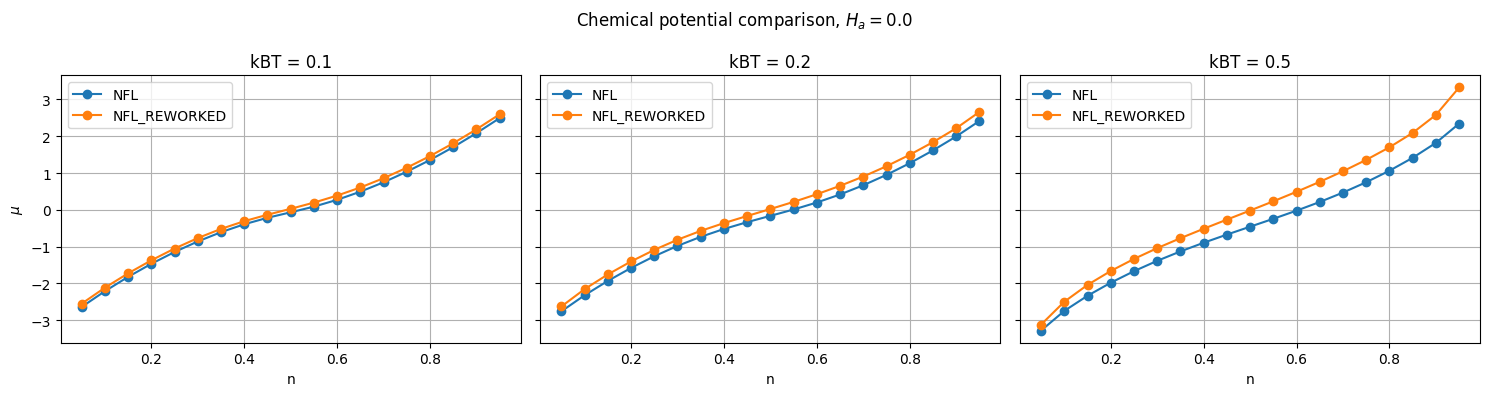

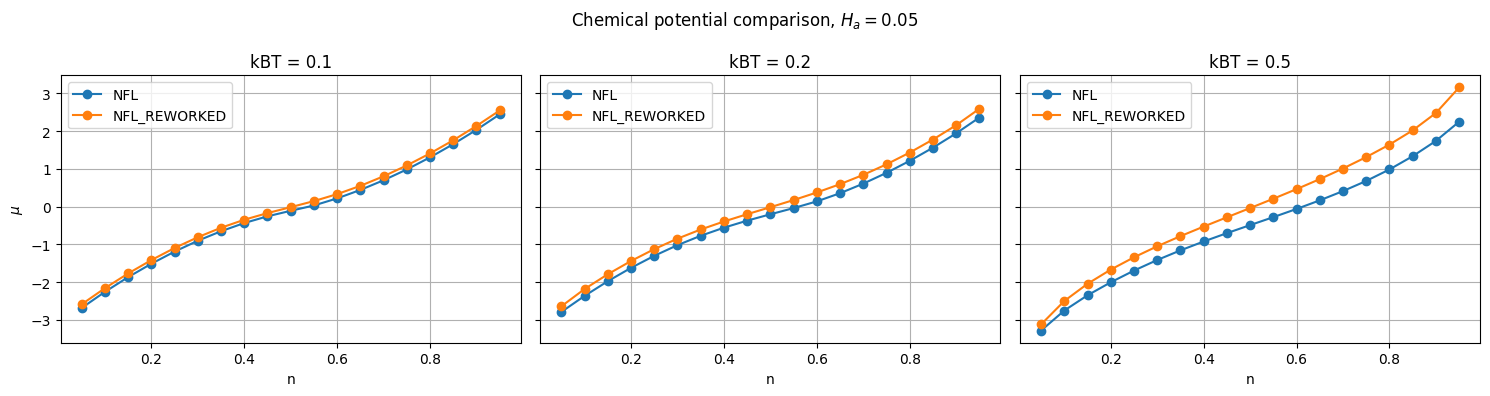

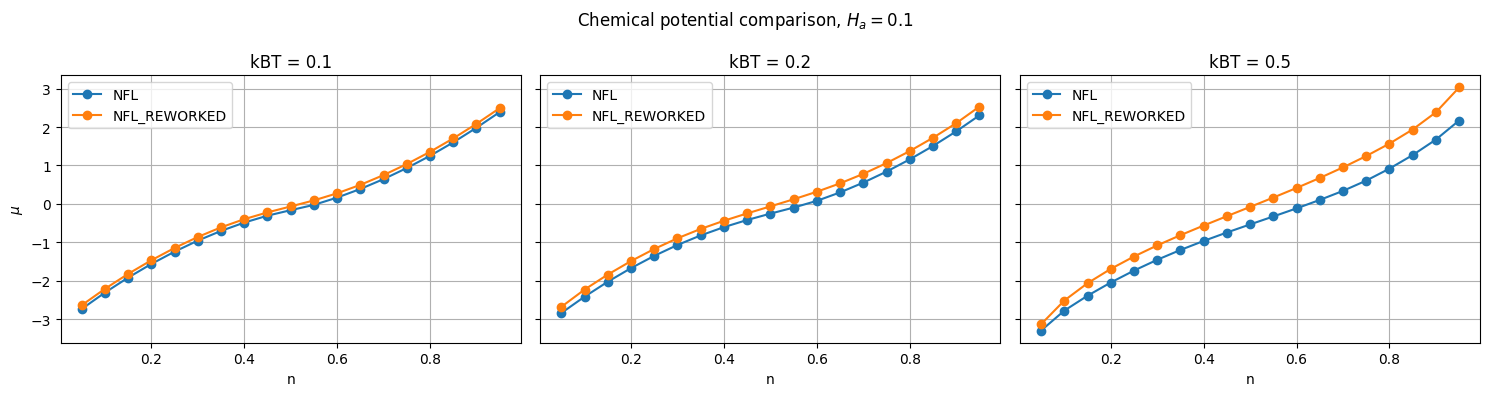

In [12]:
for H_a in H_a_vals:
    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, kBT in zip(axes, kBT_vals):
        subset = mu_df.xs((kBT, H_a), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            ax.plot(block.index.values, block["mu"].values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()

    axes[0].set_ylabel(r"$\mu$")
    plt.suptitle(rf"Chemical potential comparison, $H_a = {H_a}$")
    plt.tight_layout()


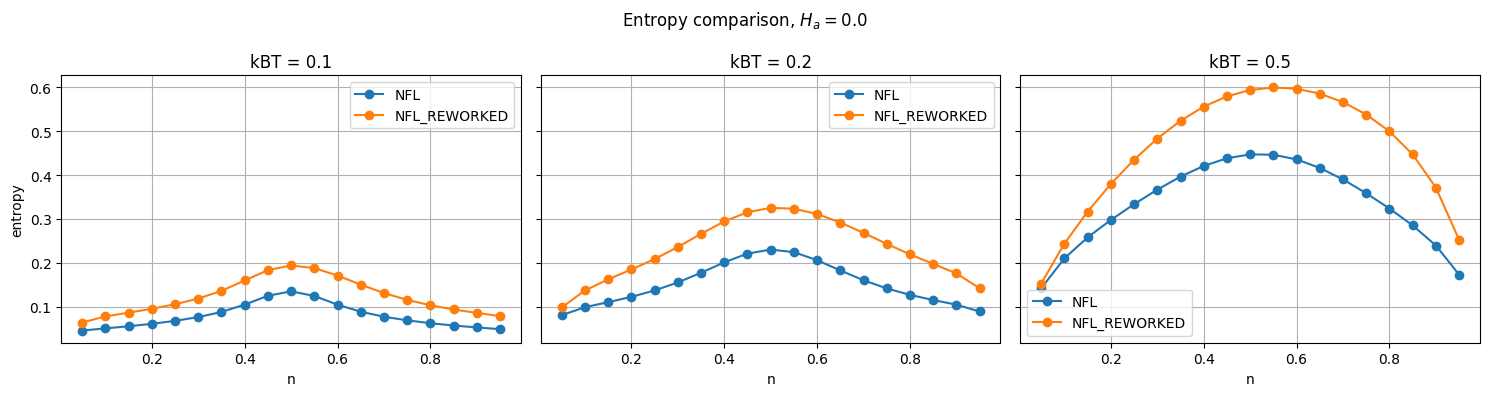

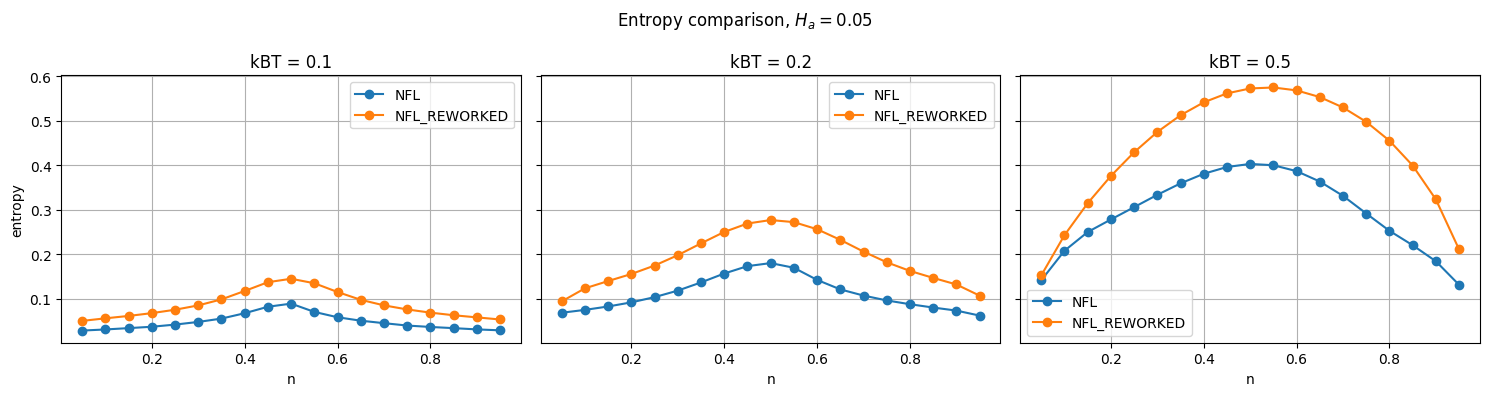

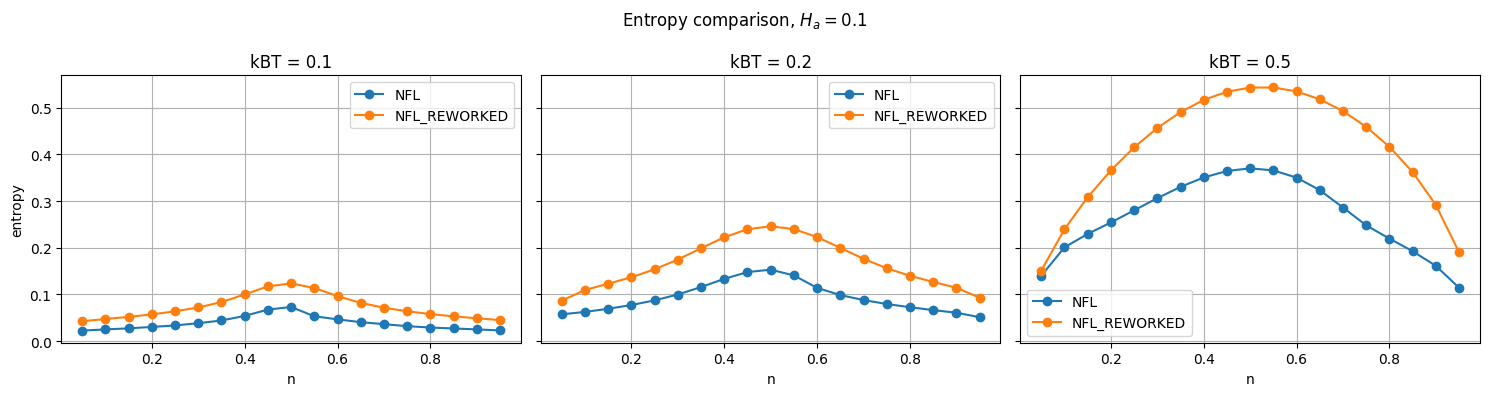

In [13]:
entropy_df = entropy(mu_df, E)

for H_a in H_a_vals:
    fig, axes = plt.subplots(1, len(kBT_vals), figsize=(5 * len(kBT_vals), 4), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, kBT in zip(axes, kBT_vals):
        subset = entropy_df.xs((kBT, H_a), level=("k_BT", "H_a"))
        for distro in distros:
            block = subset.xs(distro.name, level="distro")
            ax.plot(block.index.values, block["entropy"].values, marker="o", label=distro.name)
        ax.set_title(f"kBT = {kBT}")
        ax.set_xlabel("n")
        ax.grid(True)
        ax.legend()

    axes[0].set_ylabel("entropy")
    plt.suptitle(rf"Entropy comparison, $H_a = {H_a}$")
    plt.tight_layout()
